# Milestone 2: Exploratory Data Analysis
## Elliptic Bitcoin Dataset

**Team 11: LiveLaughLoveMachines**  
**Course:** CSCI 3052U  
**Date:** October 2, 2026

This notebook generates the 5 visualizations referenced in the Milestone 2 report.

## Dependencies
Install with: `pip install -r requirements.txt`

- pandas, numpy
- matplotlib, seaborn
- scikit-learn (for PCA)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ellipticco/elliptic-data-set")

print("Path to dataset files:", path)

data_path = os.path.join(path, "elliptic_bitcoin_dataset")

print("Dataset files:")
print(os.listdir(data_path))

Using Colab cache for faster access to the 'elliptic-data-set' dataset.
Path to dataset files: /kaggle/input/elliptic-data-set
Dataset files:
['elliptic_txs_features.csv', 'elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv']


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

features = pd.read_csv(
    os.path.join(data_path, "elliptic_txs_features.csv"),
    header=None
)

classes = pd.read_csv(
    os.path.join(data_path, "elliptic_txs_classes.csv")
)

edges = pd.read_csv(
    os.path.join(data_path, "elliptic_txs_edgelist.csv")
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load the three CSV files
features = pd.read_csv(os.path.join(data_path, 'elliptic_txs_features.csv') , header=None)
classes = pd.read_csv(os.path.join(data_path, 'elliptic_txs_classes.csv'))
edges = pd.read_csv(os.path.join(data_path, 'elliptic_txs_edgelist.csv'))

# Rename columns for readability
features.columns = ['txId', 'time_step'] + [f'feat_{i}' for i in range(1, 166)]

# Merge features with classes
df = features.merge(classes, left_on='txId', right_on='txId', how='left')
df['class'] = df['class'].replace({'unknown': 0, '1': 1, '2': 2}).astype(int)

# Style setup
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120
df

/tmp/ipykernel_2655/585591950.py:18: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['class'] = df['class'].replace({'unknown': 0, '1': 1, '2': 2}).astype(int)


,txId,time_step,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,feat_8,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,feat_165,class
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792,0
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203764,173077460,49,-0.145771,-0.163752,0.463609,-0.121970,-0.043875,-0.113002,-0.061584,-0.135803,...,-0.613614,0.241128,0.241406,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,0
203765,158577750,49,-0.165920,-0.123607,1.018602,-0.121970,-0.043875,-0.113002,-0.061584,-0.156418,...,0.010822,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,-1.760926,-1.760984,0
203766,158375402,49,-0.172014,-0.078182,1.018602,0.028105,-0.043875,0.054722,-0.061584,-0.163626,...,1.985050,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,1
203767,158654197,49,-0.172842,-0.176622,1.018602,-0.121970,-0.043875,-0.113002,-0.061584,-0.163501,...,-0.411776,1.461330,1.461369,-0.098889,-0.087490,-0.084674,-0.140597,1.519700,1.521399,0


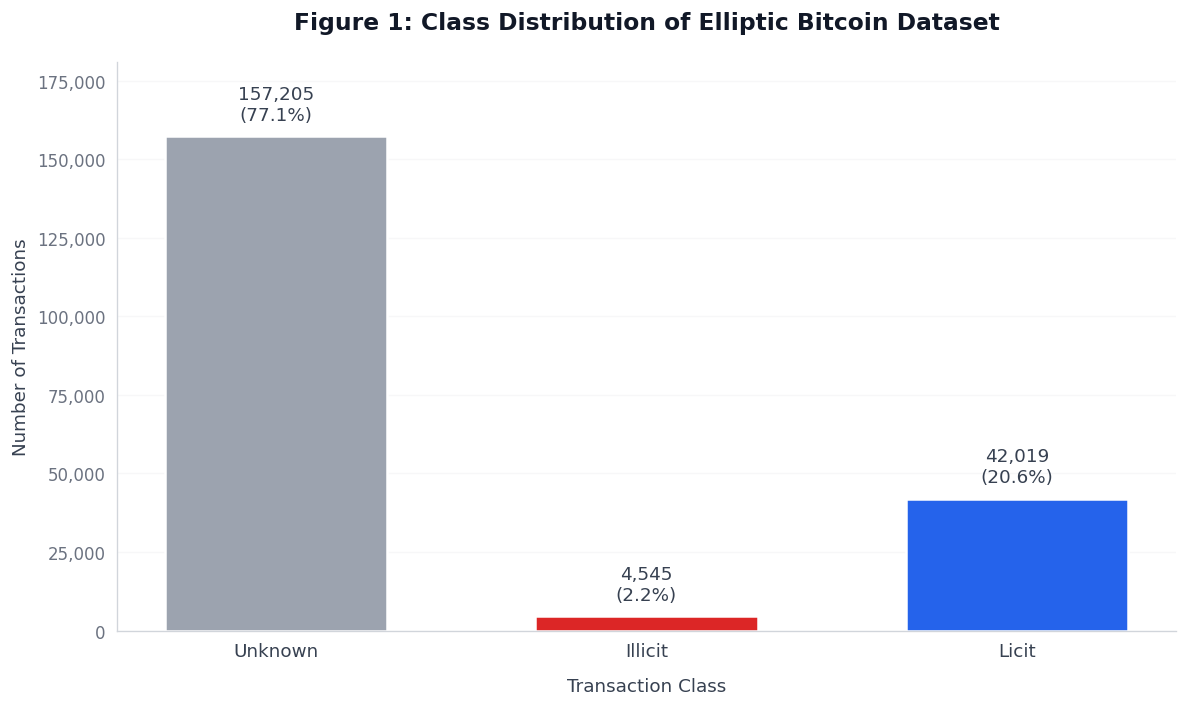

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data
labels = ['Unknown', 'Illicit', 'Licit']
counts = [157205, 4545, 42019]
colors = ['#9CA3AF', '#DC2626', '#2563EB']

# Set up figure with proper sizing
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Create bars
x_pos = np.arange(len(labels))
bars = ax.bar(x_pos, counts, color=colors, width=0.6,
              edgecolor='white', linewidth=1.5)

# Add value labels above bars with better spacing
for bar, count in zip(bars, counts):
    pct = 100 * count / sum(counts)
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 4000,
            f'{count:,}\n({pct:.1f}%)',
            ha='center', va='bottom',
            fontsize=11, fontweight='500',
            color='#374151')

# Title with proper spacing (no overlap with labels)
ax.set_title('Figure 1: Class Distribution of Elliptic Bitcoin Dataset',
             fontsize=14, fontweight='600',
             color='#111827', pad=20)

# Axis labels
ax.set_xlabel('Transaction Class', fontsize=11, color='#374151', labelpad=10)
ax.set_ylabel('Number of Transactions', fontsize=11, color='#374151')
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, fontsize=11, color='#374151')

# Clean up spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#D1D5DB')
ax.spines['bottom'].set_color('#D1D5DB')

# Subtle horizontal gridlines only
ax.yaxis.grid(True, linestyle='-', alpha=0.3, color='#E5E7EB')
ax.xaxis.grid(False)
ax.set_axisbelow(True)

# Format y-axis with commas
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.tick_params(axis='y', colors='#6B7280', labelsize=10)
ax.tick_params(axis='x', colors='#374151', labelsize=11)

# Add headroom above tallest bar so labels don't clip
ax.set_ylim(0, max(counts) * 1.15)

plt.tight_layout()
plt.savefig('fig1_class_distribution.png', dpi=150, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

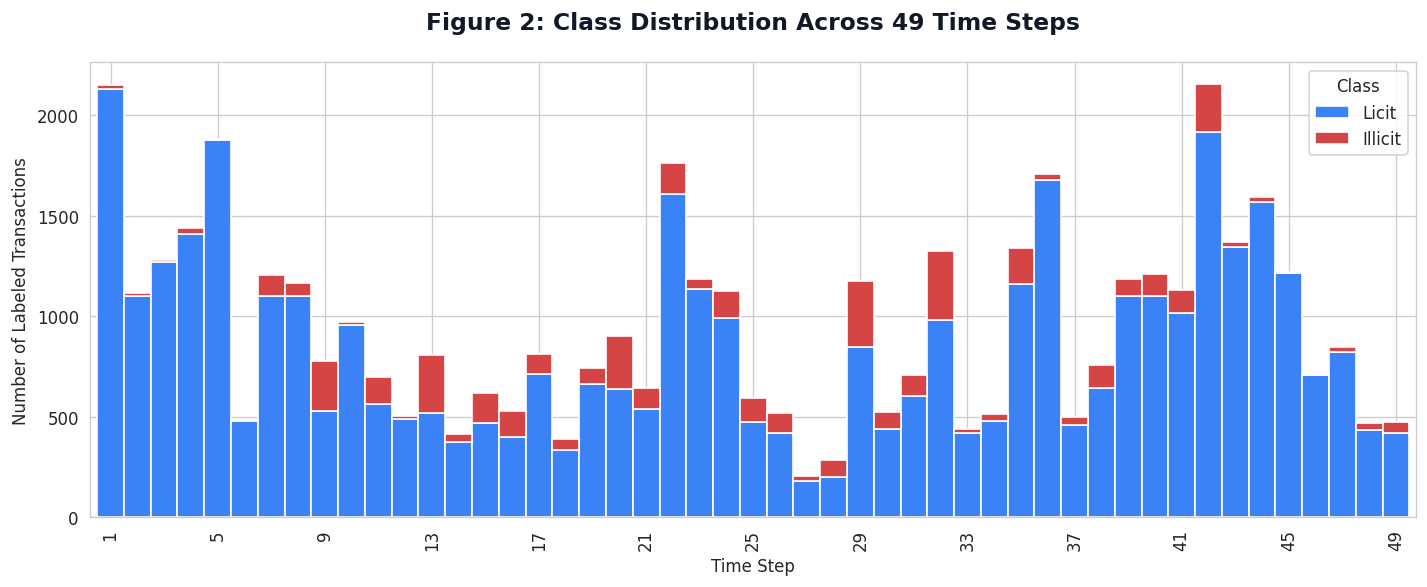

In [ ]:
labeled = df[df['class'] != 0].copy()
labeled['label_name'] = labeled['class'].map({1: 'Illicit', 2: 'Licit'})

time_class = labeled.groupby(['time_step', 'label_name']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
time_class[['Licit', 'Illicit']].plot(
    kind='bar', stacked=True, ax=ax,
    color=['#3B82F6', '#D64545'], width=1.0
)

ax.set_xlabel('Time Step')
ax.set_ylabel('Number of Labeled Transactions')
ax.set_title('Figure 2: Class Distribution Across 49 Time Steps', fontsize=14, fontweight='600', color='#111827', pad=20)
ax.legend(title='Class', loc='upper right')
ax.set_xticks(range(0, 49, 4))
plt.tight_layout()
plt.savefig('fig2_class_over_time.png', dpi=150, bbox_inches='tight')
plt.show()

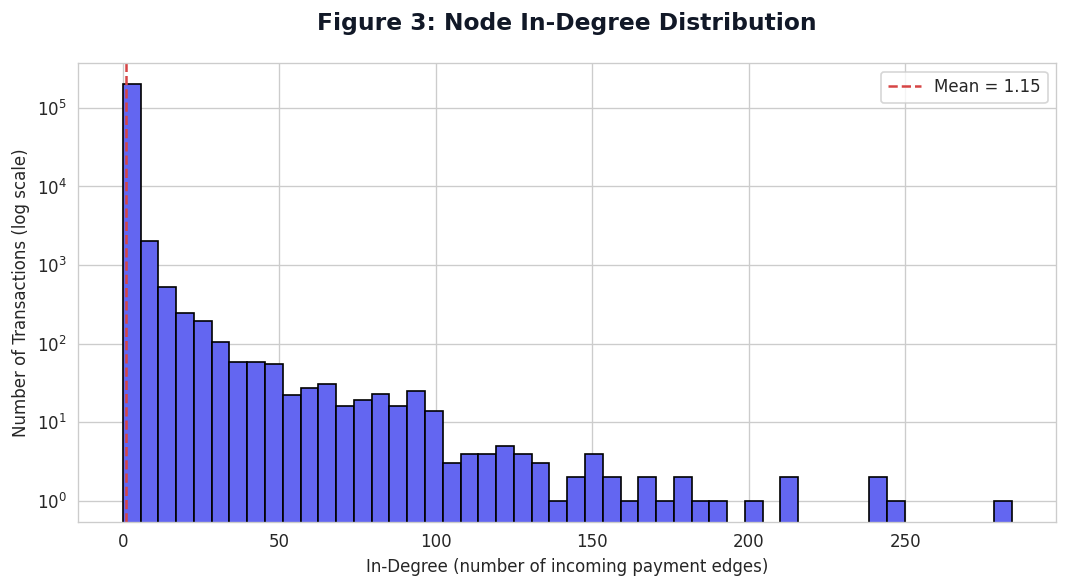

In [ ]:
from collections import Counter

in_degree = Counter(edges['txId2'])
in_deg_values = [in_degree.get(tx, 0) for tx in df['txId']]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(in_deg_values, bins=50, color='#6366F1', edgecolor='black', log=True)
ax.set_xlabel('In-Degree (number of incoming payment edges)')
ax.set_ylabel('Number of Transactions (log scale)')
ax.set_title('Figure 3: Node In-Degree Distribution', fontsize=14, fontweight='600', color='#111827', pad=20)
ax.axvline(np.mean(in_deg_values), color='#D64545', linestyle='--',
           label=f'Mean = {np.mean(in_deg_values):.2f}')
ax.legend()
plt.tight_layout()
plt.savefig('fig3_indegree.png', dpi=150, bbox_inches='tight')
plt.show()

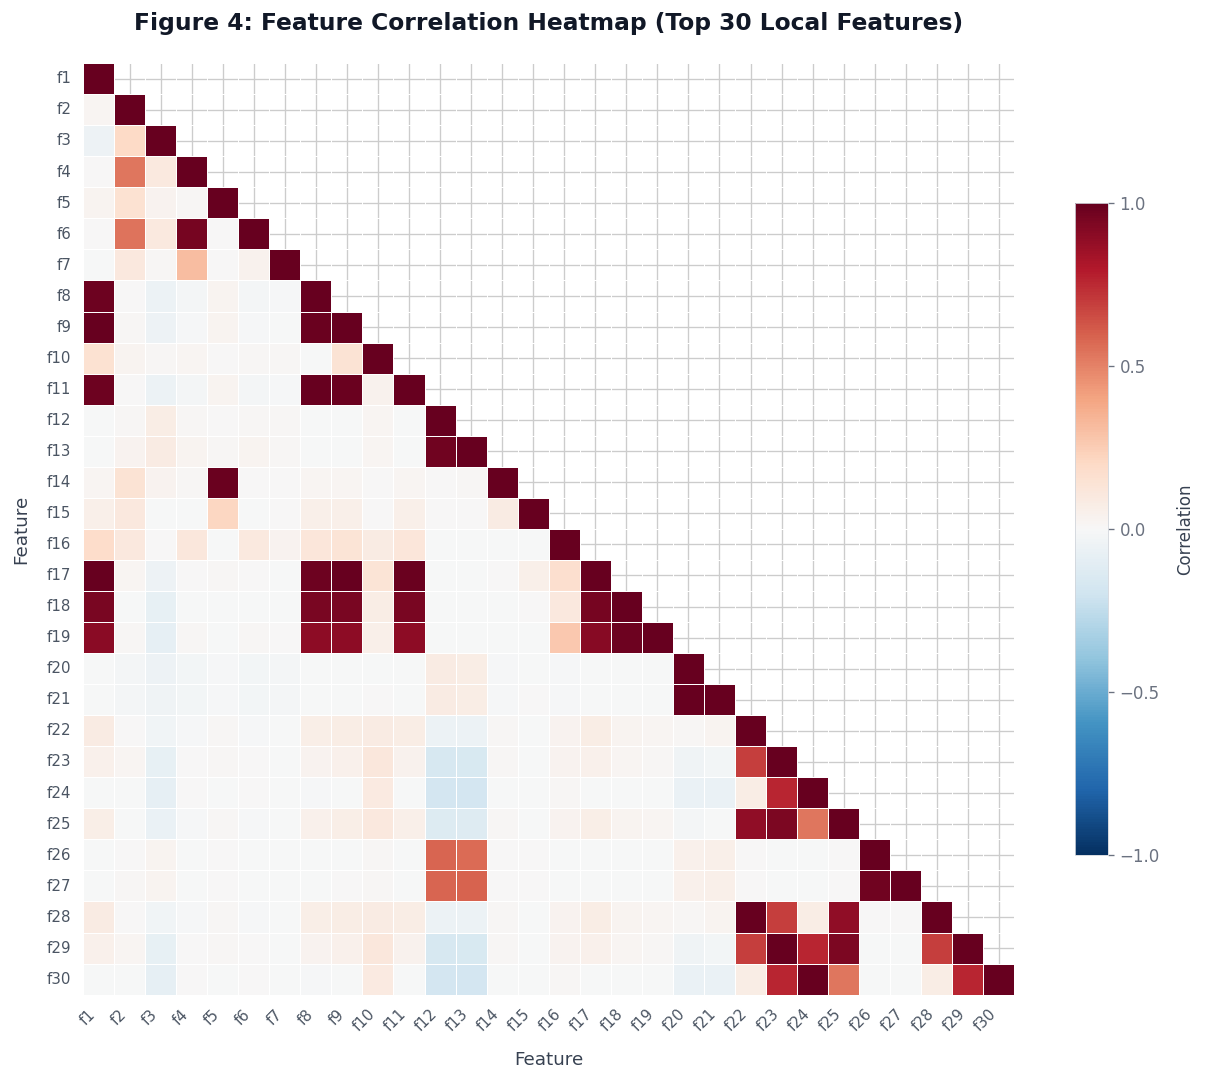

In [ ]:
# Compute correlation on the top 30 features
feat_cols = [f'feat_{i}' for i in range(1, 31)]
corr = df[feat_cols].corr()

# Nicer feature labels (shorter)
labels = [f'f{i}' for i in range(1, 31)]

# Set up figure
fig, ax = plt.subplots(figsize=(11, 9))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Mask the upper triangle to reduce visual noise
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# Create heatmap
sns.heatmap(
    corr,
    mask=mask,
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={
        'shrink': 0.7,
        'label': 'Correlation',
        'ticks': [-1, -0.5, 0, 0.5, 1]
    },
    xticklabels=labels,
    yticklabels=labels,
    ax=ax
)

# Title with spacing
ax.set_title(
    'Figure 4: Feature Correlation Heatmap (Top 30 Local Features)',
    fontsize=14, fontweight='600', color='#111827', pad=20
)

# Axis labels
ax.set_xlabel('Feature', fontsize=11, color='#374151', labelpad=10)
ax.set_ylabel('Feature', fontsize=11, color='#374151', labelpad=10)

# Rotate tick labels for readability
plt.setp(ax.get_xticklabels(), rotation=45, ha='right',
         fontsize=9, color='#4B5563')
plt.setp(ax.get_yticklabels(), rotation=0,
         fontsize=9, color='#4B5563')

# Colorbar styling
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10, colors='#6B7280')
cbar.outline.set_edgecolor('#D1D5DB')
cbar.outline.set_linewidth(0.5)
cbar.set_label('Correlation', fontsize=10, color='#374151', labelpad=10)

plt.tight_layout()
plt.savefig('fig4_corr_heatmap.png', dpi=150, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

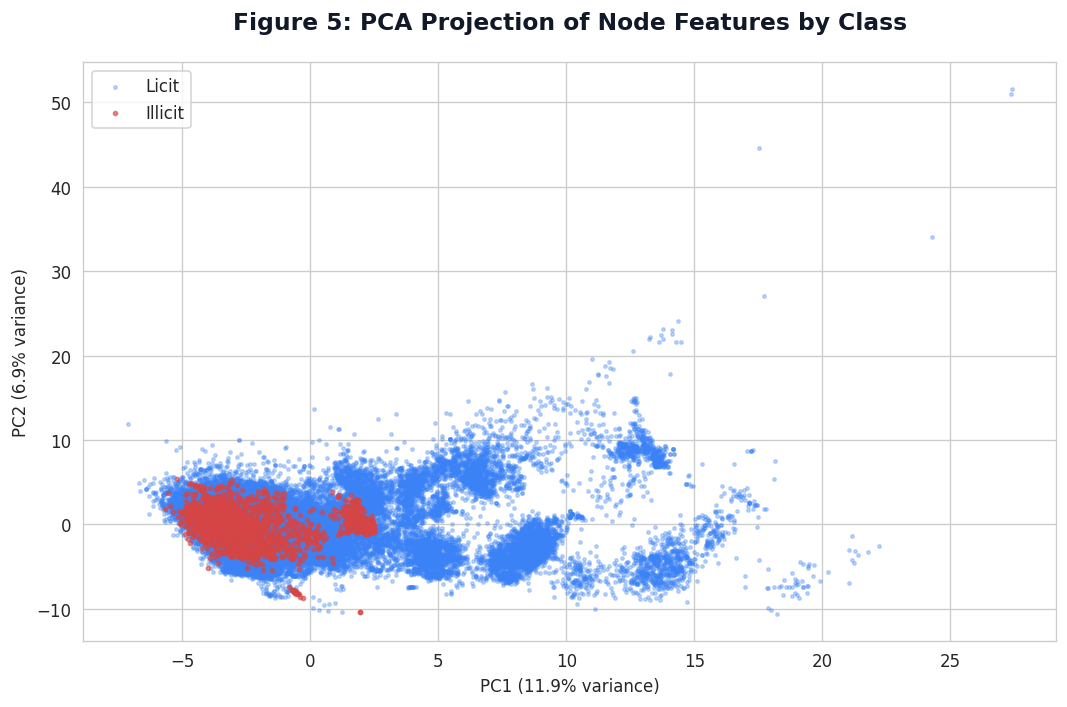

In [ ]:
labeled_df = df[df['class'] != 0].copy()
feat_matrix = labeled_df[[f'feat_{i}' for i in range(1, 166)]].values

# Standardize then PCA to 2D
scaler = StandardScaler()
feat_scaled = scaler.fit_transform(feat_matrix)

pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(feat_scaled)

labeled_df['pca_1'] = pca_result[:, 0]
labeled_df['pca_2'] = pca_result[:, 1]

fig, ax = plt.subplots(figsize=(9, 6))
licit = labeled_df[labeled_df['class'] == 2]
illicit = labeled_df[labeled_df['class'] == 1]

ax.scatter(licit['pca_1'], licit['pca_2'], s=4, alpha=0.3,
           color='#3B82F6', label='Licit')
ax.scatter(illicit['pca_1'], illicit['pca_2'], s=6, alpha=0.6,
           color='#D64545', label='Illicit')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.set_title('Figure 5: PCA Projection of Node Features by Class', fontsize=14, fontweight='600', color='#111827', pad=20)
ax.legend()
plt.tight_layout()
plt.savefig('fig5_pca_scatter.png', dpi=150, bbox_inches='tight')
plt.show()